# EPFL Machine Learning — Project 1

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MisakiTaro0414/epfl-ml-project1-2026/blob/main/run.ipynb)

This companion notebook reproduces the NumPy project in this delivery. It loads the saved model, verifies the official dataset, writes `submission.csv`, and displays the recorded validation results. Set `RETRAIN = True` below to repeat all training and model selection.

The team's original shared Colab notebook was not readable when this companion was prepared. This is a separate notebook; no team notebook has been overwritten. Execution saved in this file, if present, is from the local Python environment, not proof of a Google Colab runtime execution.

**Colab:** open the badge above and run all cells. If project source files are absent, the setup cell clones the public project repository. No Drive mount, account token, or manual source upload is required. The repository includes the trained artifacts; the large official dataset is downloaded separately.

**Local:** open this notebook in the extracted project directory. Python and NumPy are required; plotting with Matplotlib is optional. Model code uses only NumPy and the Python standard library.


In [1]:
import os
from pathlib import Path
import subprocess
import sys
import tempfile

os.environ.setdefault("OPENBLAS_NUM_THREADS", "4")
os.environ.setdefault("OMP_NUM_THREADS", "4")

REPOSITORY_URL = "https://github.com/MisakiTaro0414/epfl-ml-project1-2026.git"
required_sources = (
    "download_data.py", "run.py", "train.py", "models.py", "preprocessing.py",
    "data_utils.py", "implementations.py", "helpers.py",
)

def sources_present(directory):
    return all((directory / name).is_file() for name in required_sources)

project_dir = Path.cwd()
if not sources_present(project_dir):
    project_dir = Path(tempfile.mkdtemp(prefix="epfl-project1-")) / "project"
    subprocess.run(
        ["git", "clone", "--depth", "1", "--branch", "main", REPOSITORY_URL, str(project_dir)],
        check=True,
    )
    if not sources_present(project_dir):
        raise RuntimeError("The cloned repository is missing required project source files.")
    os.chdir(project_dir)
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))
import numpy as np
print("Project directory:", project_dir)
print("Python:", sys.version.split()[0], "NumPy:", np.__version__)


Project directory: /mnt/nlp/scratch/home/suleyman/ml_course_project1
Python: 3.12.3 NumPy: 2.5.4


## Verify the official dataset

All four CSV files and the downloaded archive are checked against their recorded SHA-256 digests. Existing valid files are reused. The download is approximately 77 MB; extracted CSVs occupy approximately 324 MB.


In [2]:
import subprocess
subprocess.run(
    [sys.executable, "download_data.py", "--data-dir", "data/dataset"],
    check=True,
)


Verified all four official CSV files in /mnt/nlp/scratch/home/suleyman/ml_course_project1/data/dataset.


CompletedProcess(args=['/mnt/nlp/scratch/home/suleyman/ml_course_project1/.venv/bin/python', 'download_data.py', '--data-dir', 'data/dataset'], returncode=0)

## Training and evaluation

By default, reuse the bundled trained model. Retraining repeats the fixed stratified training/tuning/holdout split, selects the model and classification threshold using only tuning data, evaluates the frozen choice on the holdout, and refits on all labeled rows. Runtime depends on the available CPU. Final prediction generation uses the saved artifacts.


In [3]:
RETRAIN = False
artifact_files = [
    Path("results/artifacts/config.json"),
    Path("results/artifacts/preprocessor.json"),
    Path("results/artifacts/weights.npz"),
    Path("results/metrics.json"),
]
if RETRAIN or not all(path.is_file() for path in artifact_files):
    subprocess.run(
        [sys.executable, "train.py", "--data-dir", "data/dataset", "--output-dir", "results"],
        check=True,
    )
else:
    print("Using the bundled fitted model and recorded validation results.")


Using the bundled fitted model and recorded validation results.


## Generate predictions

The inference script verifies the model artifact checksums and input column order, then preserves all test IDs and writes labels in `{-1, +1}`. No prediction is sent to AIcrowd automatically.


In [4]:
subprocess.run(
    [sys.executable, "run.py", "--data-dir", "data/dataset",
     "--artifacts", "results/artifacts", "--output", "submission.csv"],
    check=True,
)
import csv
with Path("submission.csv").open(newline="") as handle:
    reader = csv.reader(handle)
    preview = [next(reader) for _ in range(6)]
print("Prediction preview:")
for row in preview:
    print(",".join(row))


Wrote 109379 predictions to submission.csv; positives=14088
SHA256 aa418240aa687a9b3b891998a3d077b3d0918825a0a8f2b223fe378b15e1cdf2
Prediction preview:
Id,Prediction
328135,-1
328136,-1
328137,-1
328138,-1
328139,-1


## Inspect the measured results

These are local validation measurements, not competition test scores. The primary selection metric is F1; accuracy and the confusion counts are also recorded. The majority-class baseline illustrates why accuracy alone is insufficient on this imbalanced dataset.


In [5]:
import json
report = json.loads(Path("results/metrics.json").read_text())
print("Dataset:", json.dumps(report["data"], indent=2))
print("Split sizes:", report["split_sizes"])
print("Selected model:", json.dumps(report["selected"], indent=2))
print("Untouched holdout:", json.dumps(report["selected_holdout"], indent=2))
print("Holdout F1 95% bootstrap interval:", report["selected_holdout_f1_ci95"])
print("Majority baseline:", json.dumps(report["majority_holdout"], indent=2))
print("\nExperiment                         Tuning F1   Holdout F1   Holdout accuracy")
for experiment in report["experiments"]:
    print(f"{experiment['name']:<34} {experiment['tuning']['f1']:.4f}"
          f"      {experiment['holdout']['f1']:.4f}"
          f"       {experiment['holdout']['accuracy']:.4f}")


Dataset: {
  "rows": 328135,
  "raw_features": 321,
  "positives": 28975,
  "prevalence": 0.08830207079403295
}
Split sizes: {'train': 196881, 'tuning': 65627, 'holdout': 65627}
Selected model: {
  "name": "engineered_logistic_1e-05",
  "mode": "engineered",
  "kind": "logistic",
  "lambda": 1e-05,
  "features": 1136,
  "threshold": 0.21064792573451996
}
Untouched holdout: {
  "f1": 0.4213976844748222,
  "accuracy": 0.8735886144422266,
  "precision": 0.35362284911623554,
  "recall": 0.521311475409836,
  "auc": 0.8578063573692275,
  "tp": 3021,
  "fp": 5522,
  "fn": 2774,
  "tn": 54310,
  "threshold": 0.21064792573451996
}
Holdout F1 95% bootstrap interval: [0.4112741947936582, 0.43188015320952516]
Majority baseline: {
  "f1": 0.0,
  "accuracy": 0.911697929205967,
  "precision": 0.0,
  "recall": 0.0,
  "auc": 0.5,
  "tp": 0,
  "fp": 0,
  "fn": 5795,
  "tn": 59832,
  "threshold": 0.5
}

Experiment                         Tuning F1   Holdout F1   Holdout accuracy
numeric_least_squares_0  

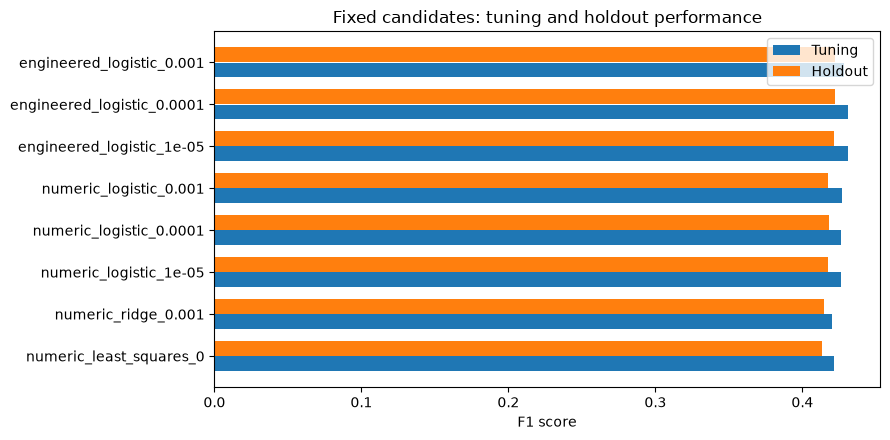

In [6]:
# Optional visualization; this library is not used for training or prediction.
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("Matplotlib is unavailable; all numeric results are shown above.")
else:
    experiments = report["experiments"]
    fig, ax = plt.subplots(figsize=(9, 4.5))
    positions = np.arange(len(experiments))
    ax.barh(positions - 0.18, [e["tuning"]["f1"] for e in experiments],
            height=0.35, label="Tuning")
    ax.barh(positions + 0.18, [e["holdout"]["f1"] for e in experiments],
            height=0.35, label="Holdout")
    ax.set_yticks(positions, labels=[e["name"] for e in experiments])
    ax.set_xlabel("F1 score")
    ax.set_title("Fixed candidates: tuning and holdout performance")
    ax.legend()
    fig.tight_layout()
    fig.savefig("results/notebook_model_comparison.png", dpi=150)
    plt.show()


## Download the prediction CSV in Colab

Set `DOWNLOAD_PREDICTIONS = True` to request a browser download. Locally, the file is already available as `submission.csv`. Upload it to your team's competition account after reviewing the results and report. The report's author names and the final public repository link must match your team.


In [7]:
DOWNLOAD_PREDICTIONS = False
if DOWNLOAD_PREDICTIONS:
    try:
        from google.colab import files
    except ImportError:
        print("Local prediction file:", Path("submission.csv").resolve())
    else:
        files.download("submission.csv")
else:
    print("Ready:", Path("submission.csv").resolve())


Ready: /mnt/nlp/scratch/home/suleyman/ml_course_project1/submission.csv
